# Healthcare Claims Analytics
**Portfolio project — all data is fully synthetic (no real patient information).**

## Business context
A health plan needs to understand *where its medical spend goes*: which members, providers, and diagnosis groups drive cost, how utilization (ER visits) trends, and whether spend is concentrating. This analysis builds the KPI foundation for value-based care and cost-containment work: PMPM, ER visits per 1,000, provider spend concentration, and high-cost claimant share.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

REPO = Path.cwd()
if REPO.name == "notebooks":
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "src"))

from analysis import (
    cost_by_claim_type, cost_by_diagnosis, data_quality_checks,
    er_rate_per_1k, high_cost_claimant_share, load_data,
    monthly_paid_trend, pmpm, top_providers, total_member_months,
)
from data_cleaning import clean_claims

sns.set_theme(style="whitegrid")
SAVE_DPI = 150
IMAGES = REPO / "images"
IMAGES.mkdir(exist_ok=True)

data = load_data(str(REPO / "data"))
members, providers, claims_raw = data["members"], data["providers"], data["claims"]
print(f"members:      {len(members):,}")
print(f"providers:    {len(providers):,}")
print(f"claims (raw): {len(claims_raw):,}")
claims_raw.head()

/home/hatch/workspace/github/.venv-claims/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


members:      4,000
providers:    120
claims (raw): 15,023


,claim_id,member_id,provider_id,service_date,claim_type,diagnosis_group,billed_amount,paid_amount,claim_status
0,C010209,M3602,P005,2024-04-30,outpatient,Musculoskeletal,474.27,206.70,paid
1,C009437,M1468,P057,2023-10-15,outpatient,Preventive,185.22,81.69,paid
2,C003016,M2234,P044,2023-05-25,outpatient,Musculoskeletal,252.70,151.14,paid
3,C011539,M2601,P091,2023-07-01,outpatient,Mental Health,107.14,62.10,paid
4,C014221,M2906,P040,2023-09-01,inpatient,Musculoskeletal,24812.89,13173.74,paid


## Data modeling — star schema

The flat claims extract is modeled as a star schema (DDL in `sql/analysis_queries.sql`):

```
dim_member (member_id PK) ──┐
                            ├─► fact_claims (claim_id PK)
dim_provider (provider_id PK) ┘        │  measures: billed_amount, paid_amount
dim_date (date_key PK) ────────────────┘  degenerate dims: claim_type, diagnosis_group, claim_status
```

`dim_date` is derived from `service_date`. Below: shape check + foreign-key validation.

In [2]:
for name, df, key in [("dim_member", members, "member_id"),
                       ("dim_provider", providers, "provider_id")]:
    print(f"{name}: {len(df):,} rows | PK unique: {df[key].is_unique}")

claims = claims_raw.copy()
claims["date_key"] = claims["service_date"].dt.date
orphan_prov = (~claims["provider_id"].isin(set(providers["provider_id"]))).sum()
orphan_mem = (~claims["member_id"].isin(set(members["member_id"]))).sum()
print(f"fact_claims: {len(claims):,} rows")
print(f"orphan provider keys: {orphan_prov} | orphan member keys: {orphan_mem}")
print(f"date range: {claims['service_date'].min().date()} → {claims['service_date'].max().date()}")

dim_member: 4,000 rows | PK unique: True
dim_provider: 120 rows | PK unique: True
fact_claims: 15,023 rows
orphan provider keys: 5 | orphan member keys: 0
date range: 2023-01-01 → 2024-12-30


## Data-quality checks

Claims feeds always carry noise. Running the standard DQ battery (mirrors `sql/analysis_queries.sql` §6) before any KPI work:

In [3]:
dq = data_quality_checks(claims_raw, providers, members)
dq

,check,violation_rows
0,duplicate_claim_id,20
1,negative_paid_amount,8
2,orphan_provider_id,5
3,orphan_member_id,0
4,null_service_date,0
5,future_service_date,0
6,paid_exceeds_billed_x2,0


In [4]:
cleaned = clean_claims(claims_raw, providers)
claims = cleaned["claims"]
rejects = cleaned["rejects"]
print("DQ report:")
for k, v in cleaned["dq_report"].items():
    print(f"  {k}: {v:,}" if isinstance(v, int) else f"  {k}: {v}")
print(f"\nQuarantined orphan rows: {len(rejects)} (routed to provider-master remediation)")
claims.head(3)

DQ report:
  rows_raw: 15,023
  duplicate_claim_rows_removed: 10
  adjustment_rows_negative_paid: 8
  orphan_provider_rows_quarantined: 5
  rows_null_service_date: 0
  rows_null_paid_amount: 0
  rows_clean: 15,008

Quarantined orphan rows: 5 (routed to provider-master remediation)


,claim_id,member_id,provider_id,service_date,claim_type,diagnosis_group,billed_amount,paid_amount,claim_status,is_adjustment
0,C010209,M3602,P005,2024-04-30,outpatient,Musculoskeletal,474.27,206.70,paid,False
1,C009437,M1468,P057,2023-10-15,outpatient,Preventive,185.22,81.69,paid,False
2,C003016,M2234,P044,2023-05-25,outpatient,Musculoskeletal,252.70,151.14,paid,False


## Exploratory analysis — claim mix and paid distribution

First: how do claim *counts* compare to *spend* by claim type? In health data these are almost never proportional.

In [5]:
mix = cost_by_claim_type(claims)
mix["pct_of_claims"] = mix["claim_count"] / mix["claim_count"].sum() * 100
mix["pct_of_spend"] = mix["total_paid"] / mix["total_paid"].sum() * 100
mix.round(1)

,claim_type,total_paid,claim_count,avg_paid,median_paid,pct_of_claims,pct_of_spend
0,inpatient,27501126.3,1220,22541.9,11392.6,8.1,82.5
1,ER,2737591.5,1351,2026.3,1270.0,9.0,8.2
2,outpatient,2625259.9,8229,319.0,205.7,54.9,7.9
3,pharmacy,482291.6,4200,114.8,81.0,28.0,1.4


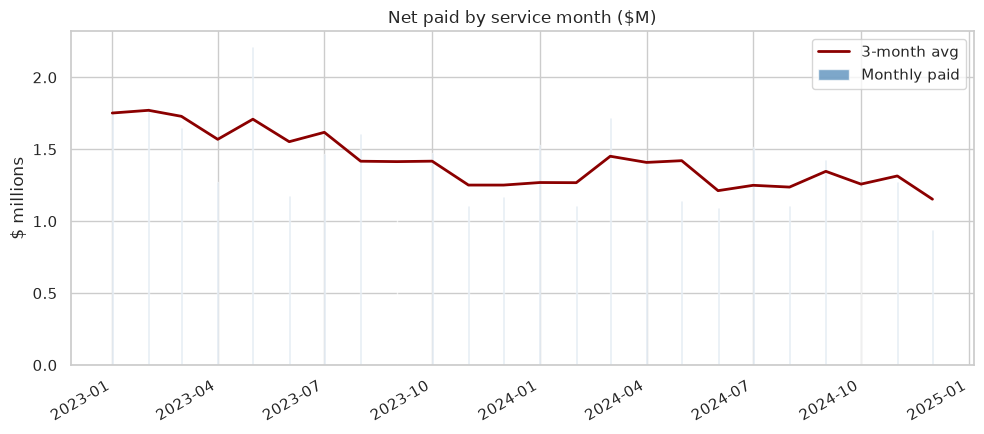

In [6]:
trend = monthly_paid_trend(claims)
trend["ma_3m"] = trend["total_paid"].rolling(3, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(trend["month"], trend["total_paid"] / 1e6, color="steelblue", alpha=0.7, label="Monthly paid")
ax.plot(trend["month"], trend["ma_3m"] / 1e6, color="darkred", linewidth=2, label="3-month avg")
ax.set_title("Net paid by service month ($M)")
ax.set_ylabel("$ millions")
ax.legend()
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
fig.savefig(IMAGES / "monthly_paid_trend.png", dpi=SAVE_DPI)
plt.show()

## Cost-driver analysis

Which diagnosis groups and providers concentrate the spend? This is the view a cost-containment team acts on.

In [7]:
diag = cost_by_diagnosis(claims)
diag[["diagnosis_group", "claim_count", "total_paid", "avg_paid", "share_of_spend"]].round(2)

,diagnosis_group,claim_count,total_paid,avg_paid,share_of_spend
0,Musculoskeletal,2596,8779929.57,3382.10,0.26
1,Cardiovascular,3142,7877602.24,2507.19,0.24
2,Oncology,234,5180717.02,22139.82,0.16
3,Pregnancy,174,4564363.19,26231.97,0.14
4,Respiratory,1862,4559907.94,2448.93,0.14
5,Mental Health,2047,805946.58,393.72,0.02
6,Diabetes,2608,642017.48,246.17,0.02
7,Other,1007,533630.12,529.92,0.02
8,Preventive,1330,402155.19,302.37,0.01


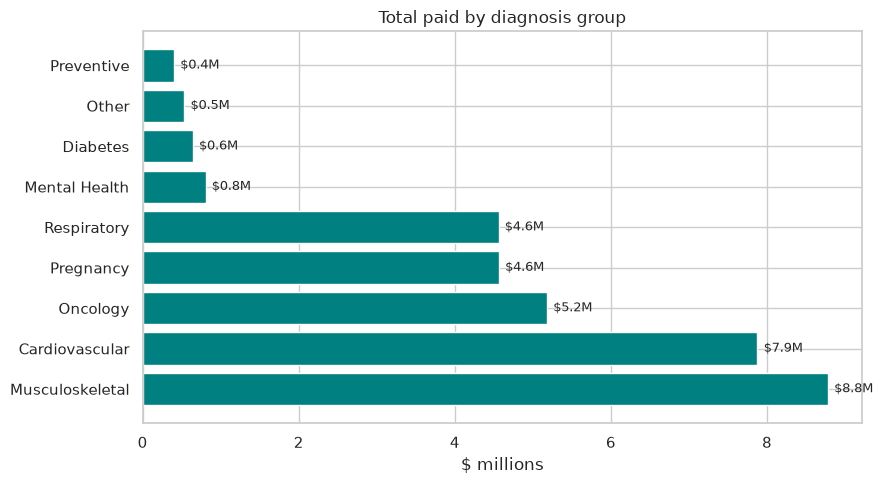

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
top_diag = diag.head(9)
ax.barh(top_diag["diagnosis_group"], top_diag["total_paid"] / 1e6, color="teal")
ax.set_xlabel("$ millions")
ax.set_title("Total paid by diagnosis group")
for i, v in enumerate(top_diag["total_paid"] / 1e6):
    ax.text(v + 0.08, i, f"${v:.1f}M", va="center", fontsize=9)
fig.tight_layout()
fig.savefig(IMAGES / "cost_by_diagnosis.png", dpi=SAVE_DPI)
plt.show()

In [9]:
tp = top_providers(claims, providers, 10)
print(f"Top-10 providers drive {tp['share_of_spend'].sum()*100:.1f}% of total spend\n")
tp[["provider_name", "provider_type", "claim_count", "total_paid", "share_of_spend"]].round(3)

Top-10 providers drive 65.8% of total spend



,provider_name,provider_type,claim_count,total_paid,share_of_spend
0,Sunrise Medical Center 13,Hospital,174,2768611.78,0.083
1,Riverbend Medical Center 07,Hospital,178,2670167.74,0.080
2,Brightpath Medical Center 05,Hospital,168,2300683.27,0.069
3,Northgate Medical Center 09,Hospital,173,2119534.30,0.064
4,Summit Medical Center 11,Hospital,171,2076437.33,0.062
5,Sunrise Medical Center 01,Hospital,173,2064757.10,0.062
6,Summit Medical Center 14,Hospital,157,2027512.50,0.061
7,Lakeside Medical Center 06,Hospital,161,2001183.75,0.060
8,Metro Medical Center 12,Hospital,171,1980569.95,0.059
9,Northgate Medical Center 15,Hospital,191,1927734.98,0.058


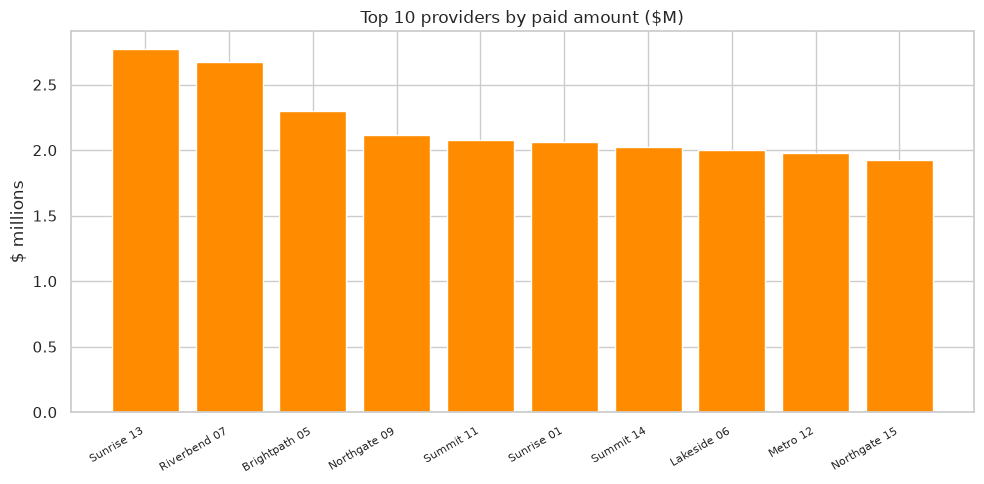

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
labels = tp["provider_name"].str.replace(" Medical Center", "")
ax.bar(labels, tp["total_paid"] / 1e6, color="darkorange")
ax.set_title("Top 10 providers by paid amount ($M)")
ax.set_ylabel("$ millions")
plt.xticks(rotation=30, ha="right", fontsize=8)
fig.tight_layout()
fig.savefig(IMAGES / "provider_concentration.png", dpi=SAVE_DPI)
plt.show()

## KPI summary

The four headline KPIs (definitions in `dashboard/README.md`), computed on cleaned data:

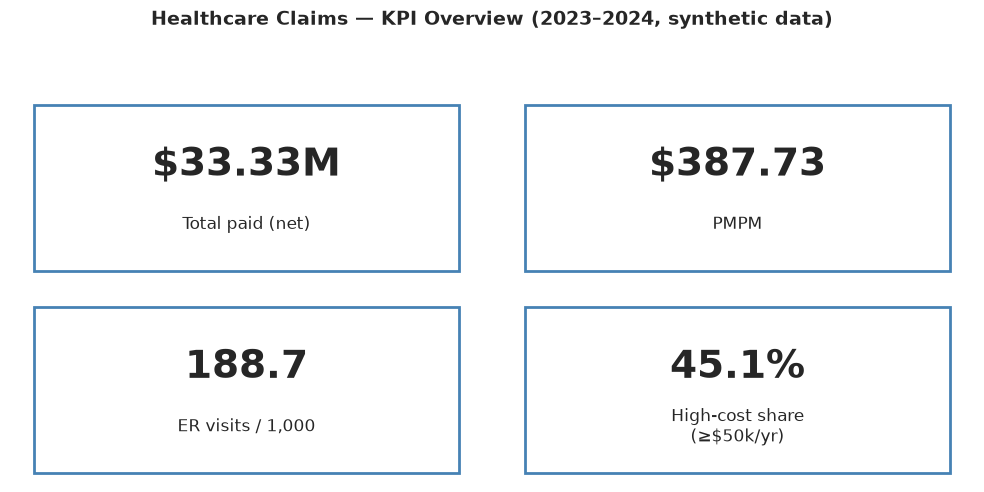

In [11]:
total_paid = claims["paid_amount"].sum()
pmpm_val = pmpm(claims, members)
er_1k = er_rate_per_1k(claims, members)
hc = high_cost_claimant_share(claims)

kpis = [
    ("Total paid (net)", f"${total_paid/1e6:.2f}M"),
    ("PMPM", f"${pmpm_val:.2f}"),
    ("ER visits / 1,000", f"{er_1k:.1f}"),
    ("High-cost share\n(\u2265$50k/yr)", f"{hc['share_of_spend']:.1f}%"),
]
fig, axes = plt.subplots(2, 2, figsize=(10, 5))
fig.suptitle("Healthcare Claims \u2014 KPI Overview (2023\u20132024, synthetic data)",
             fontsize=14, fontweight="bold")
for ax, (label, value) in zip(axes.flat, kpis):
    ax.axis("off")
    ax.text(0.5, 0.62, value, ha="center", va="center", fontsize=28,
            fontweight="bold", transform=ax.transAxes)
    ax.text(0.5, 0.30, label, ha="center", va="center", fontsize=12,
            transform=ax.transAxes)
    ax.add_patch(plt.Rectangle((0.05, 0.05), 0.9, 0.9, fill=False,
                               edgecolor="steelblue", linewidth=2,
                               transform=ax.transAxes))
fig.tight_layout(rect=[0, 0, 1, 0.92])
fig.savefig(IMAGES / "kpi_overview.png", dpi=SAVE_DPI)
plt.show()

In [12]:
print("HEADLINE METRICS (cleaned data, 2023-2024)")
print(f"  Members / member-months : {len(members):,} / {total_member_months(members):,}")
print(f"  Claims analyzed         : {len(claims):,}")
print(f"  Total paid (net)        : ${total_paid:,.0f}")
print(f"  PMPM                    : ${pmpm_val:.2f}")
print(f"  ER visits / 1,000       : {er_1k:.1f}")
inp = mix.loc[mix['claim_type'] == 'inpatient'].iloc[0]
print(f"  Inpatient share of spend: {inp['pct_of_spend']:.1f}% (from {inp['pct_of_claims']:.1f}% of claims)")
print(f"  Top cost driver         : {diag.iloc[0]['diagnosis_group']} "
      f"(${diag.iloc[0]['total_paid']/1e6:.2f}M, {diag.iloc[0]['share_of_spend']*100:.1f}% of spend)")
print(f"  High-cost member-years  : {hc['high_cost_member_years']:,} ({hc['pct_of_member_years']:.1f}%) \u2192 "
      f"{hc['share_of_spend']:.1f}% of spend")

HEADLINE METRICS (cleaned data, 2023-2024)
  Members / member-months : 4,000 / 85,971
  Claims analyzed         : 15,008
  Total paid (net)        : $33,333,392
  PMPM                    : $387.73
  ER visits / 1,000       : 188.7
  Inpatient share of spend: 82.5% (from 8.1% of claims)
  Top cost driver         : Musculoskeletal ($8.78M, 26.3% of spend)
  High-cost member-years  : 142 (2.5%) → 45.1% of spend


## Key insights

1. **Spend is extremely concentrated in inpatient care** — 8.1% of claims drive 82.5% of paid amounts, the classic claims skew. Any cost-containment lever must start with inpatient drivers.
2. **Musculoskeletal and cardiovascular conditions are the top diagnosis-group cost drivers** — together $16.7M, ~50% of spend — the natural focus for care-management programs.
3. **A small high-cost cohort drives nearly half the spend**: 2.5% of member-years (≥$50k/yr) account for 45.1% of total paid — the standard case-management target population.
4. **Provider spend is concentrated**: the top 10 providers (all hospitals) capture 65.8% of spend, the largest single provider at 8.3% — relevant for network contracting and value-based negotiations.
5. **ER utilization runs 188.7 visits per 1,000 member-years** — worth benchmarking against plan targets; potentially avoidable ER use is a typical follow-up analysis.

## Reproducibility
Re-run `src/generate_data.py` (seed 42) and this notebook end-to-end to reproduce every number and chart.